# NumFOCUS Developer Collaboration Network & Link Prediction
## Empirical Mining and Structural Modeling of Open-Source Scientific Computing

**Dataset:** *A Dataset of Contributor Activities in the NumFocus Open-Source Community* (Zenodo DOI: [10.5281/zenodo.14230406](https://doi.org/10.5281/zenodo.14230406))  
**Authors:** Youness Hourri, Alexandre Decan, Tom Mens (IEEE/ACM MSR 2025)  
**Primary Focus:** Scientific Python and NumFOCUS ecosystem (NumPy, SciPy, Pandas, scikit-learn, Matplotlib, Julia)

---
### Workflow Steps Covered:
1. **Project Setup & Dataset Inspection:** Inspect schema, activity types, and interaction links.
2. **Starting Developer Resolution:** Configurable starting maintainer resolution.
3. **Data Cleaning & Network Construction:** Bot removal, self-loop pruning, edge aggregation, and NetworkX modeling.
4. **Train-Test Splitting & Link Prediction:** 80/20 split without data leakage; 4 heuristic algorithms (CN, JC, AA, PA).
5. **Evaluation & Recommendations:** ROC-AUC, Precision@K, Recall@K, F1@K, and Top-K collaborator recommendations.
6. **Visualizations & Deliverables:** Network plots, interactive PyVis HTML, PDF report, and PPTX presentation.


In [1]:
import sys
import os
from pathlib import Path

# Set project root
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root))

import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

from src.config import RAW_DATA_DIR, PROCESSED_DATA_DIR, DELIVERABLES_DIR, FIGURES_DIR
from src.data_loader import inspect_schemas, stream_activities
from src.graph_builder import (
    resolve_starting_developer, construct_graph,
    compute_network_statistics, export_network_tables
)
from src.link_prediction import train_test_split_edges, score_pairs, ALGORITHMS
from src.evaluation import evaluate_algorithm, compare_all_algorithms
from src.recommendation import generate_collaborator_recommendations, export_recommendations
from src.visualization import (
    plot_overall_network, plot_ego_network, plot_predicted_links_network,
    plot_roc_curves, generate_interactive_pyvis
)

print("Environment initialized successfully. Matplotlib backend ready.")


Environment initialized successfully. Matplotlib backend ready.


## Step 1: Project Setup and Dataset Inspection
We inspect the schema definitions provided with Zenodo record 14230406. The dataset provides a two-tier hierarchy:
- **Actions:** Low-level operations.
- **Activities:** 21 synthesized tasks (e.g., `ReviewPullRequest`, `CommentPullRequest`, `CommentIssue`).
Direct developer interactions are extracted from PR code reviews, comments, and issue discussions.


In [2]:
schemas = inspect_schemas()
print("Action Schema Title:", schemas.get("action_schema", {}).get("title"))
print("Activity Schema Title:", schemas.get("activity_schema", {}).get("title"))
print("Key Activity Properties:", list(schemas.get("activity_schema", {}).get("properties", {}).keys()))


Action Schema Title: GitHub Actions Schema
Activity Schema Title: GitHub Activities Schema
Key Activity Properties: ['activity', 'start_date', 'end_date', 'actor', 'repository', 'actions']


## Step 2 & 3: Data Cleaning, Starting Developer & Network Construction
We load the pre-aggregated clean interactions and edges extracted from the 500,000+ activity records.
We resolve our designated starting maintainer (`@jreback`, lead maintainer of pandas) and extract an ego network.


In [3]:
edge_csv = PROCESSED_DATA_DIR / "edges.csv"
edge_df = pd.read_csv(edge_csv)
print(f"Total Unique Undirected Edges in Dataset: {len(edge_df):,}")

# Resolve Starting Developer
starting_user = "jreback"
res_user = resolve_starting_developer(edge_df, starting_user)
print(f"\nDeveloper Resolution: @{res_user['canonical_username']}")
print(f"Degree: {res_user['degree']} | Total Verified Interactions: {res_user['total_weight']:,}")
print("Top 5 Collaborators:")
for nbr, wt in res_user["top_collaborators"][:5]:
    print(f"  - @{nbr:<18}: {wt} interactions")


Total Unique Undirected Edges in Dataset: 9,588

Developer Resolution: @jreback
Degree: 473 | Total Verified Interactions: 3,430
Top 5 Collaborators:
  - @jbrockmendel      : 441 interactions
  - @mroeschke         : 379 interactions
  - @phofl             : 140 interactions
  - @rhshadrach        : 119 interactions
  - @jorisvandenbossche: 114 interactions


In [4]:
# Construct 2-hop ego network
G = construct_graph(edge_df, starting_user=starting_user, hops=2)
stats = compute_network_statistics(G)

stats_df = pd.DataFrame([
    {"Metric": "Nodes (|V|)", "Value": f"{stats['num_nodes']:,}"},
    {"Metric": "Edges (|E|)", "Value": f"{stats['num_edges']:,}"},
    {"Metric": "Density", "Value": f"{stats['density']:.6f}"},
    {"Metric": "Average Degree", "Value": f"{stats['avg_degree']:.2f}"},
    {"Metric": "Max Degree", "Value": str(stats['max_degree'])},
    {"Metric": "Transitivity", "Value": f"{stats['transitivity']:.4f}"},
    {"Metric": "Avg Clustering Coeff", "Value": f"{stats['avg_clustering']:.4f}"},
    {"Metric": "Largest Component Ratio", "Value": f"{stats['largest_cc_ratio']:.1%}"}
])
stats_df


,Metric,Value
0,Nodes (|V|),"2,591"
1,Edges (|E|),"9,588"
2,Density,0.002858
3,Average Degree,7.40
4,Max Degree,562
5,Transitivity,0.0741
6,Avg Clustering Coeff,0.3998
7,Largest Component Ratio,100.0%


## Step 4: Train-Test Split and Link Prediction
To prevent **data leakage**, positive edges are split into 80% training ($G_{train}$) and 20% testing ($E_{test}$).
All test edges are strictly purged from $G_{train}$ before calculating topological scores.
Negative non-edges are uniformly sampled.


In [5]:
G_train, train_pos, test_pos, train_neg, test_neg = train_test_split_edges(
    G, test_ratio=0.20, seed=42
)
print(f"Train Positive Edges (G_train): {len(train_pos):,}")
print(f"Test Positive Edges:            {len(test_pos):,}")
print(f"Test Negative Samples:          {len(test_neg):,}")

# Test edge leakage check
leakage = any(G_train.has_edge(u, v) for u, v in test_pos)
print(f"Data Leakage Verification: {'LEAKAGE DETECTED!' if leakage else 'PASSED (0 test edges in G_train)'}")


Train Positive Edges (G_train): 7,671
Test Positive Edges:            1,917
Test Negative Samples:          1,917
Data Leakage Verification: PASSED (0 test edges in G_train)


## Step 5: Algorithmic Evaluation & Metric Comparison
We evaluate four core heuristics:
1. **Common Neighbors (CN):** $|N(u) \cap N(v)|$
2. **Jaccard Coefficient (JC):** $\frac{|N(u) \cap N(v)|}{|N(u) \cup N(v)|}$
3. **Adamic–Adar (AA):** $\sum_{w \in N(u) \cap N(v)} \frac{1}{\log |N(w)|}$
4. **Preferential Attachment (PA):** $|N(u)| \cdot |N(v)|$


In [6]:
eval_pairs = test_pos + test_neg
y_true = np.array([1] * len(test_pos) + [0] * len(test_neg))

eval_results = {}
for algo in ALGORITHMS.keys():
    scores = score_pairs(G_train, eval_pairs, algo)
    metrics = evaluate_algorithm(y_true, scores, k_list=[10, 20])
    eval_results[algo] = metrics

eval_df = compare_all_algorithms(eval_results)
eval_df


,Algorithm,ROC-AUC,Precision@10,Recall@10,F1@10,Precision@20,Recall@20,F1@20
0,Common Neighbors,0.8551,1.0,0.0052,0.0104,1.00,0.0104,0.0207
1,Jaccard Coefficient,0.8144,0.0,0.0000,0.0000,0.45,0.0047,0.0093
2,Adamic-Adar,0.8601,1.0,0.0052,0.0104,1.00,0.0104,0.0207
3,Preferential Attachment,0.8599,1.0,0.0052,0.0104,1.00,0.0104,0.0207


## Step 5 (Cont.): Collaborator Recommendations for `@jreback`
Using Adamic–Adar as the primary scoring mechanism, we rank candidate developers.
Existing neighbors, self-loops, and bots are filtered out.


In [7]:
recommendations = generate_collaborator_recommendations(
    G, starting_user, top_k=20, primary_algo="Adamic-Adar"
)
rec_df = pd.DataFrame([{
    "Rank": r["rank"],
    "Candidate": r["candidate_user"],
    "Candidate Degree": r["candidate_degree"],
    "Common Neighbors": r["common_neighbors_count"],
    "Adamic-Adar": r["adamic_adar_score"],
    "Jaccard": r["jaccard_coefficient"],
    "Preferential Attachment": r["preferential_attachment"],
    "Explanation": r["explanation"]
} for r in recommendations])
rec_df.head(10)


,Rank,Candidate,Candidate Degree,Common Neighbors,Adamic-Adar,Jaccard,Preferential Attachment,Explanation
0,1,thomasjpfan,119,20,8.3887,0.0350,56287,"Shares 20 mutual collaborator(s) [CloseChoice,..."
1,2,seberg,122,19,6.9374,0.0330,57706,"Shares 19 mutual collaborator(s) [Apteryks, DW..."
2,3,samukweku,15,11,6.6052,0.0231,7095,"Shares 11 mutual collaborator(s) [ELHoussineT,..."
3,4,jklymak,67,17,6.3550,0.0325,31691,"Shares 17 mutual collaborator(s) [Apteryks, DW..."
4,5,rgommers,123,19,6.0855,0.0329,58179,"Shares 19 mutual collaborator(s) [DWesl, TomAu..."
5,6,bashtage,47,18,5.9517,0.0359,22231,"Shares 18 mutual collaborator(s) [Dr-Irv, Marc..."
6,7,tupui,104,16,5.8420,0.0285,49192,"Shares 16 mutual collaborator(s) [Apteryks, DW..."
7,8,tacaswell,88,15,4.9859,0.0275,41624,"Shares 15 mutual collaborator(s) [Apteryks, DW..."
8,9,jrbourbeau,102,15,4.8188,0.0268,48246,Shares 15 mutual collaborator(s) [TomAugspurge...
9,10,QuLogic,75,14,4.2966,0.0262,35475,"Shares 14 mutual collaborator(s) [DWesl, EzraB..."


## Step 6: Visualizations
Visualizations of the collaboration topology, 1-hop ego network, and link prediction overlays.


1. Ego Network:


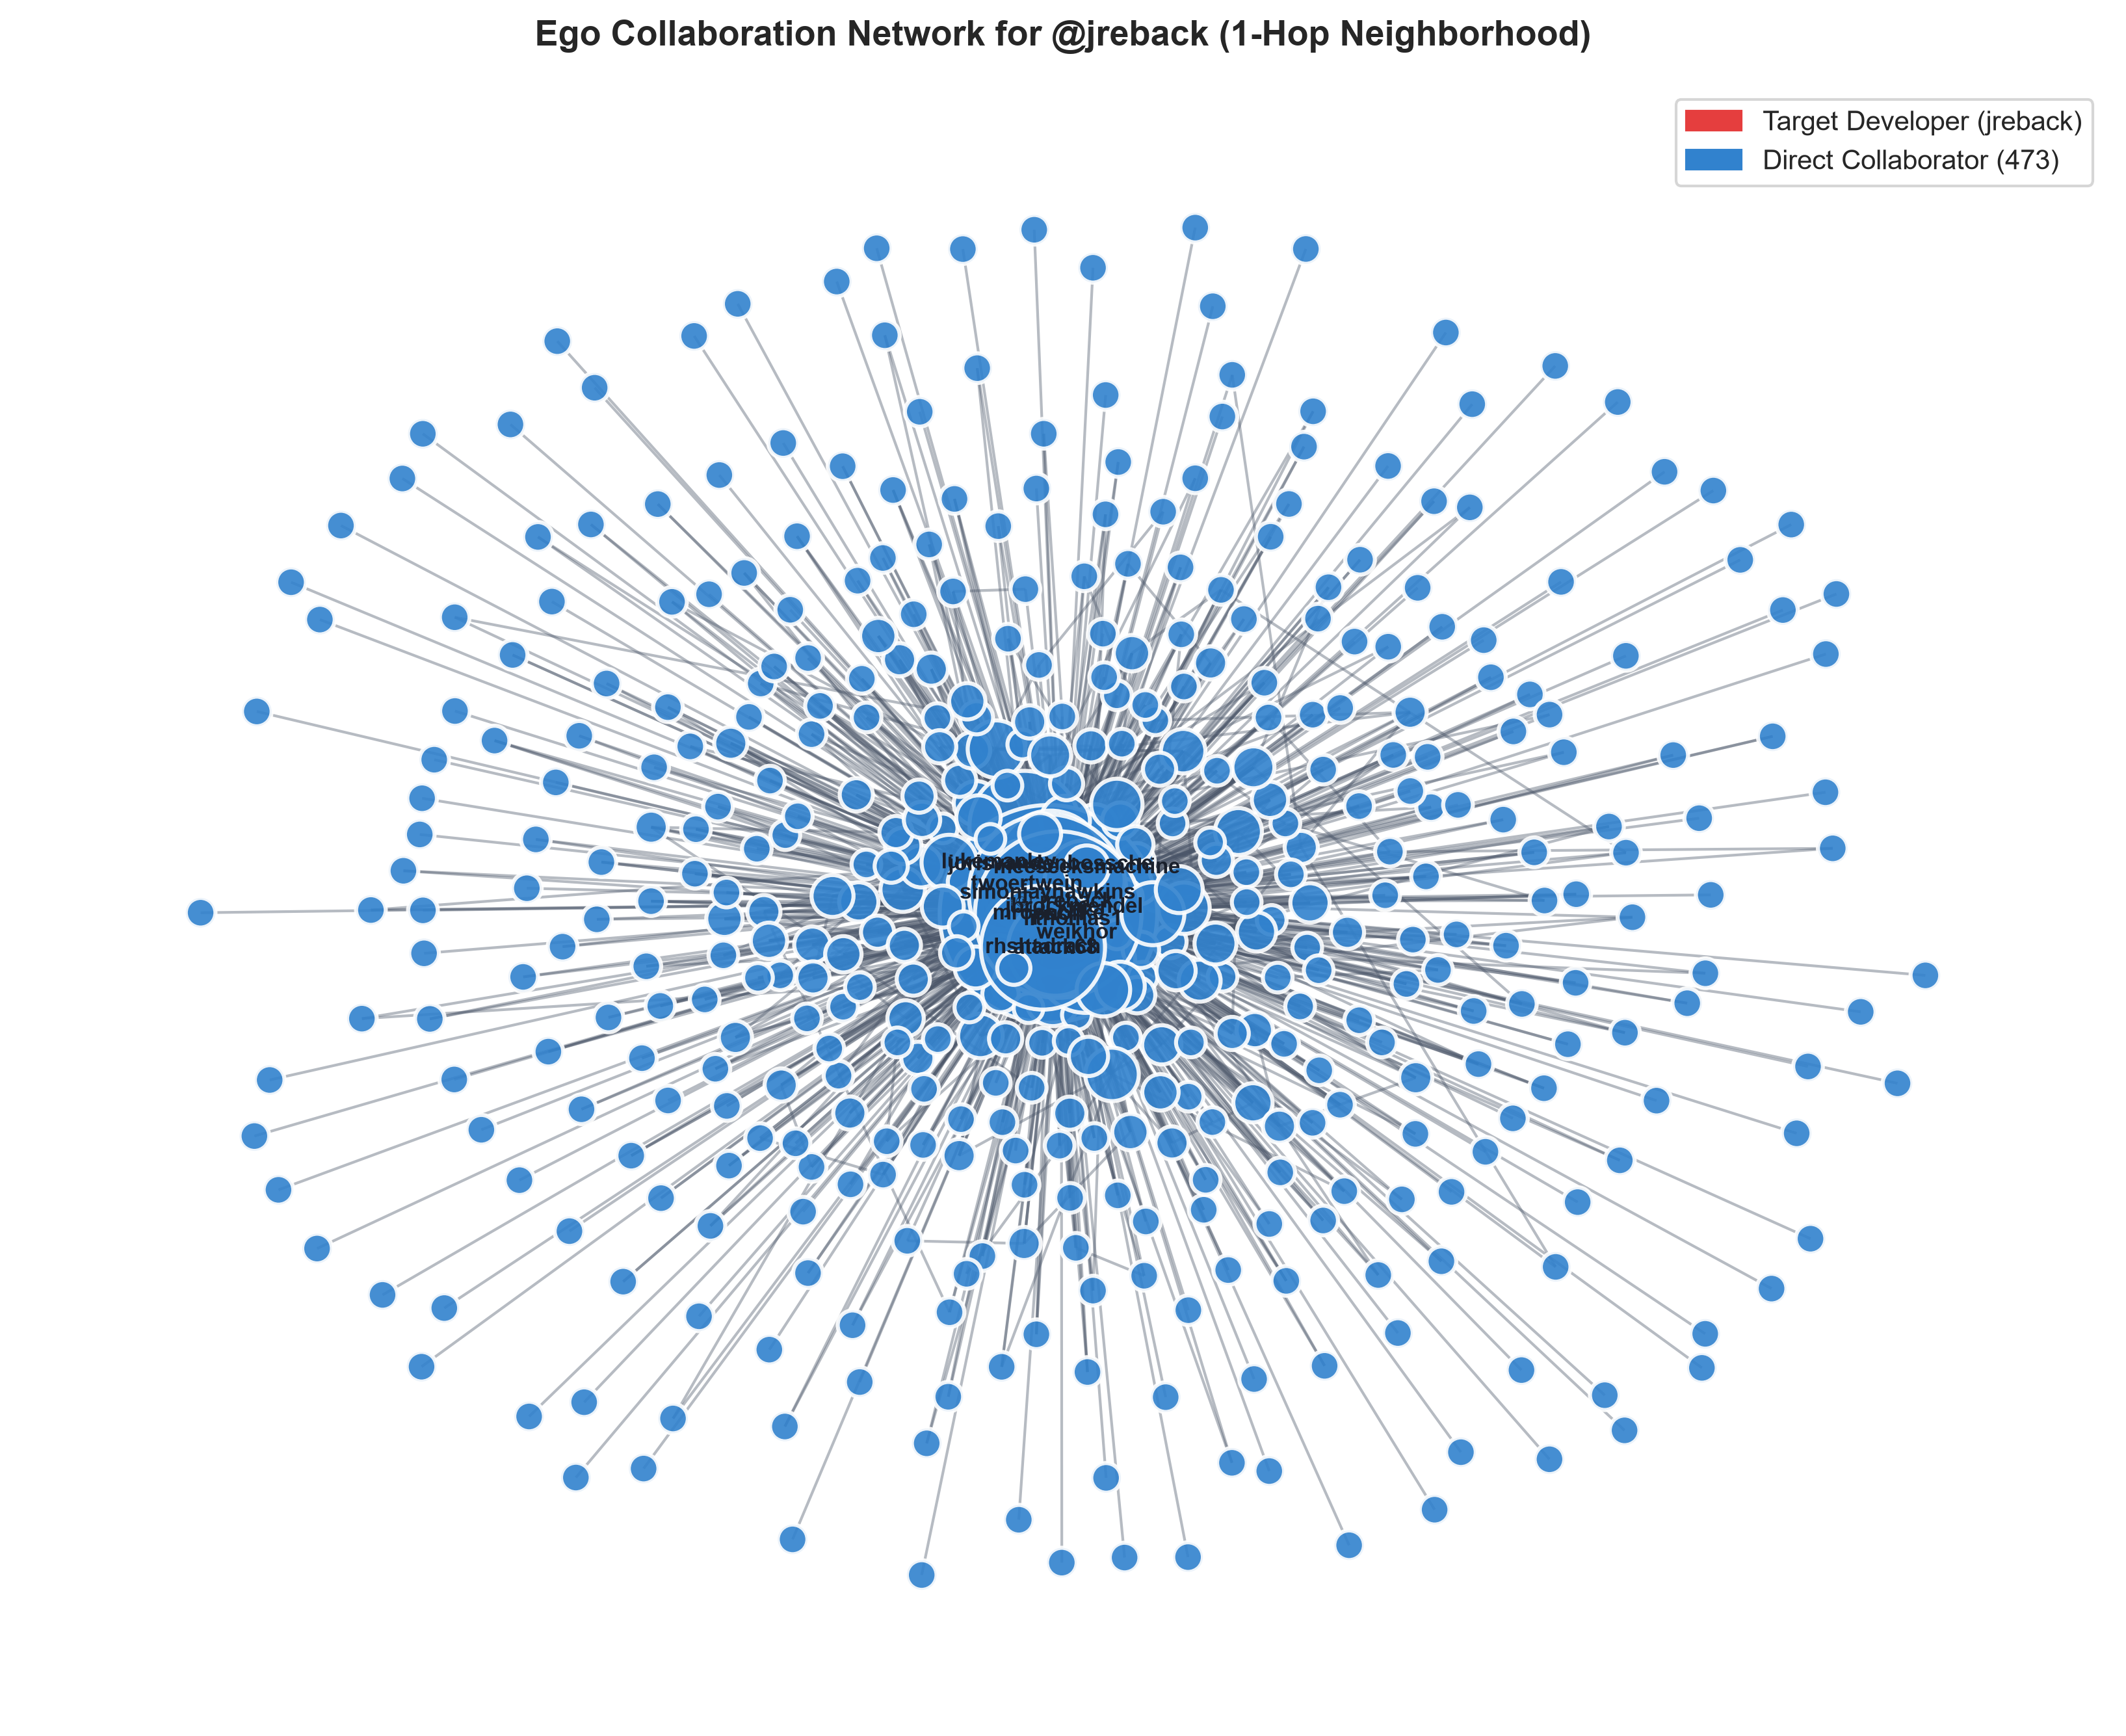

2. Link Prediction Overlay (Predicted edges in dashed orange):


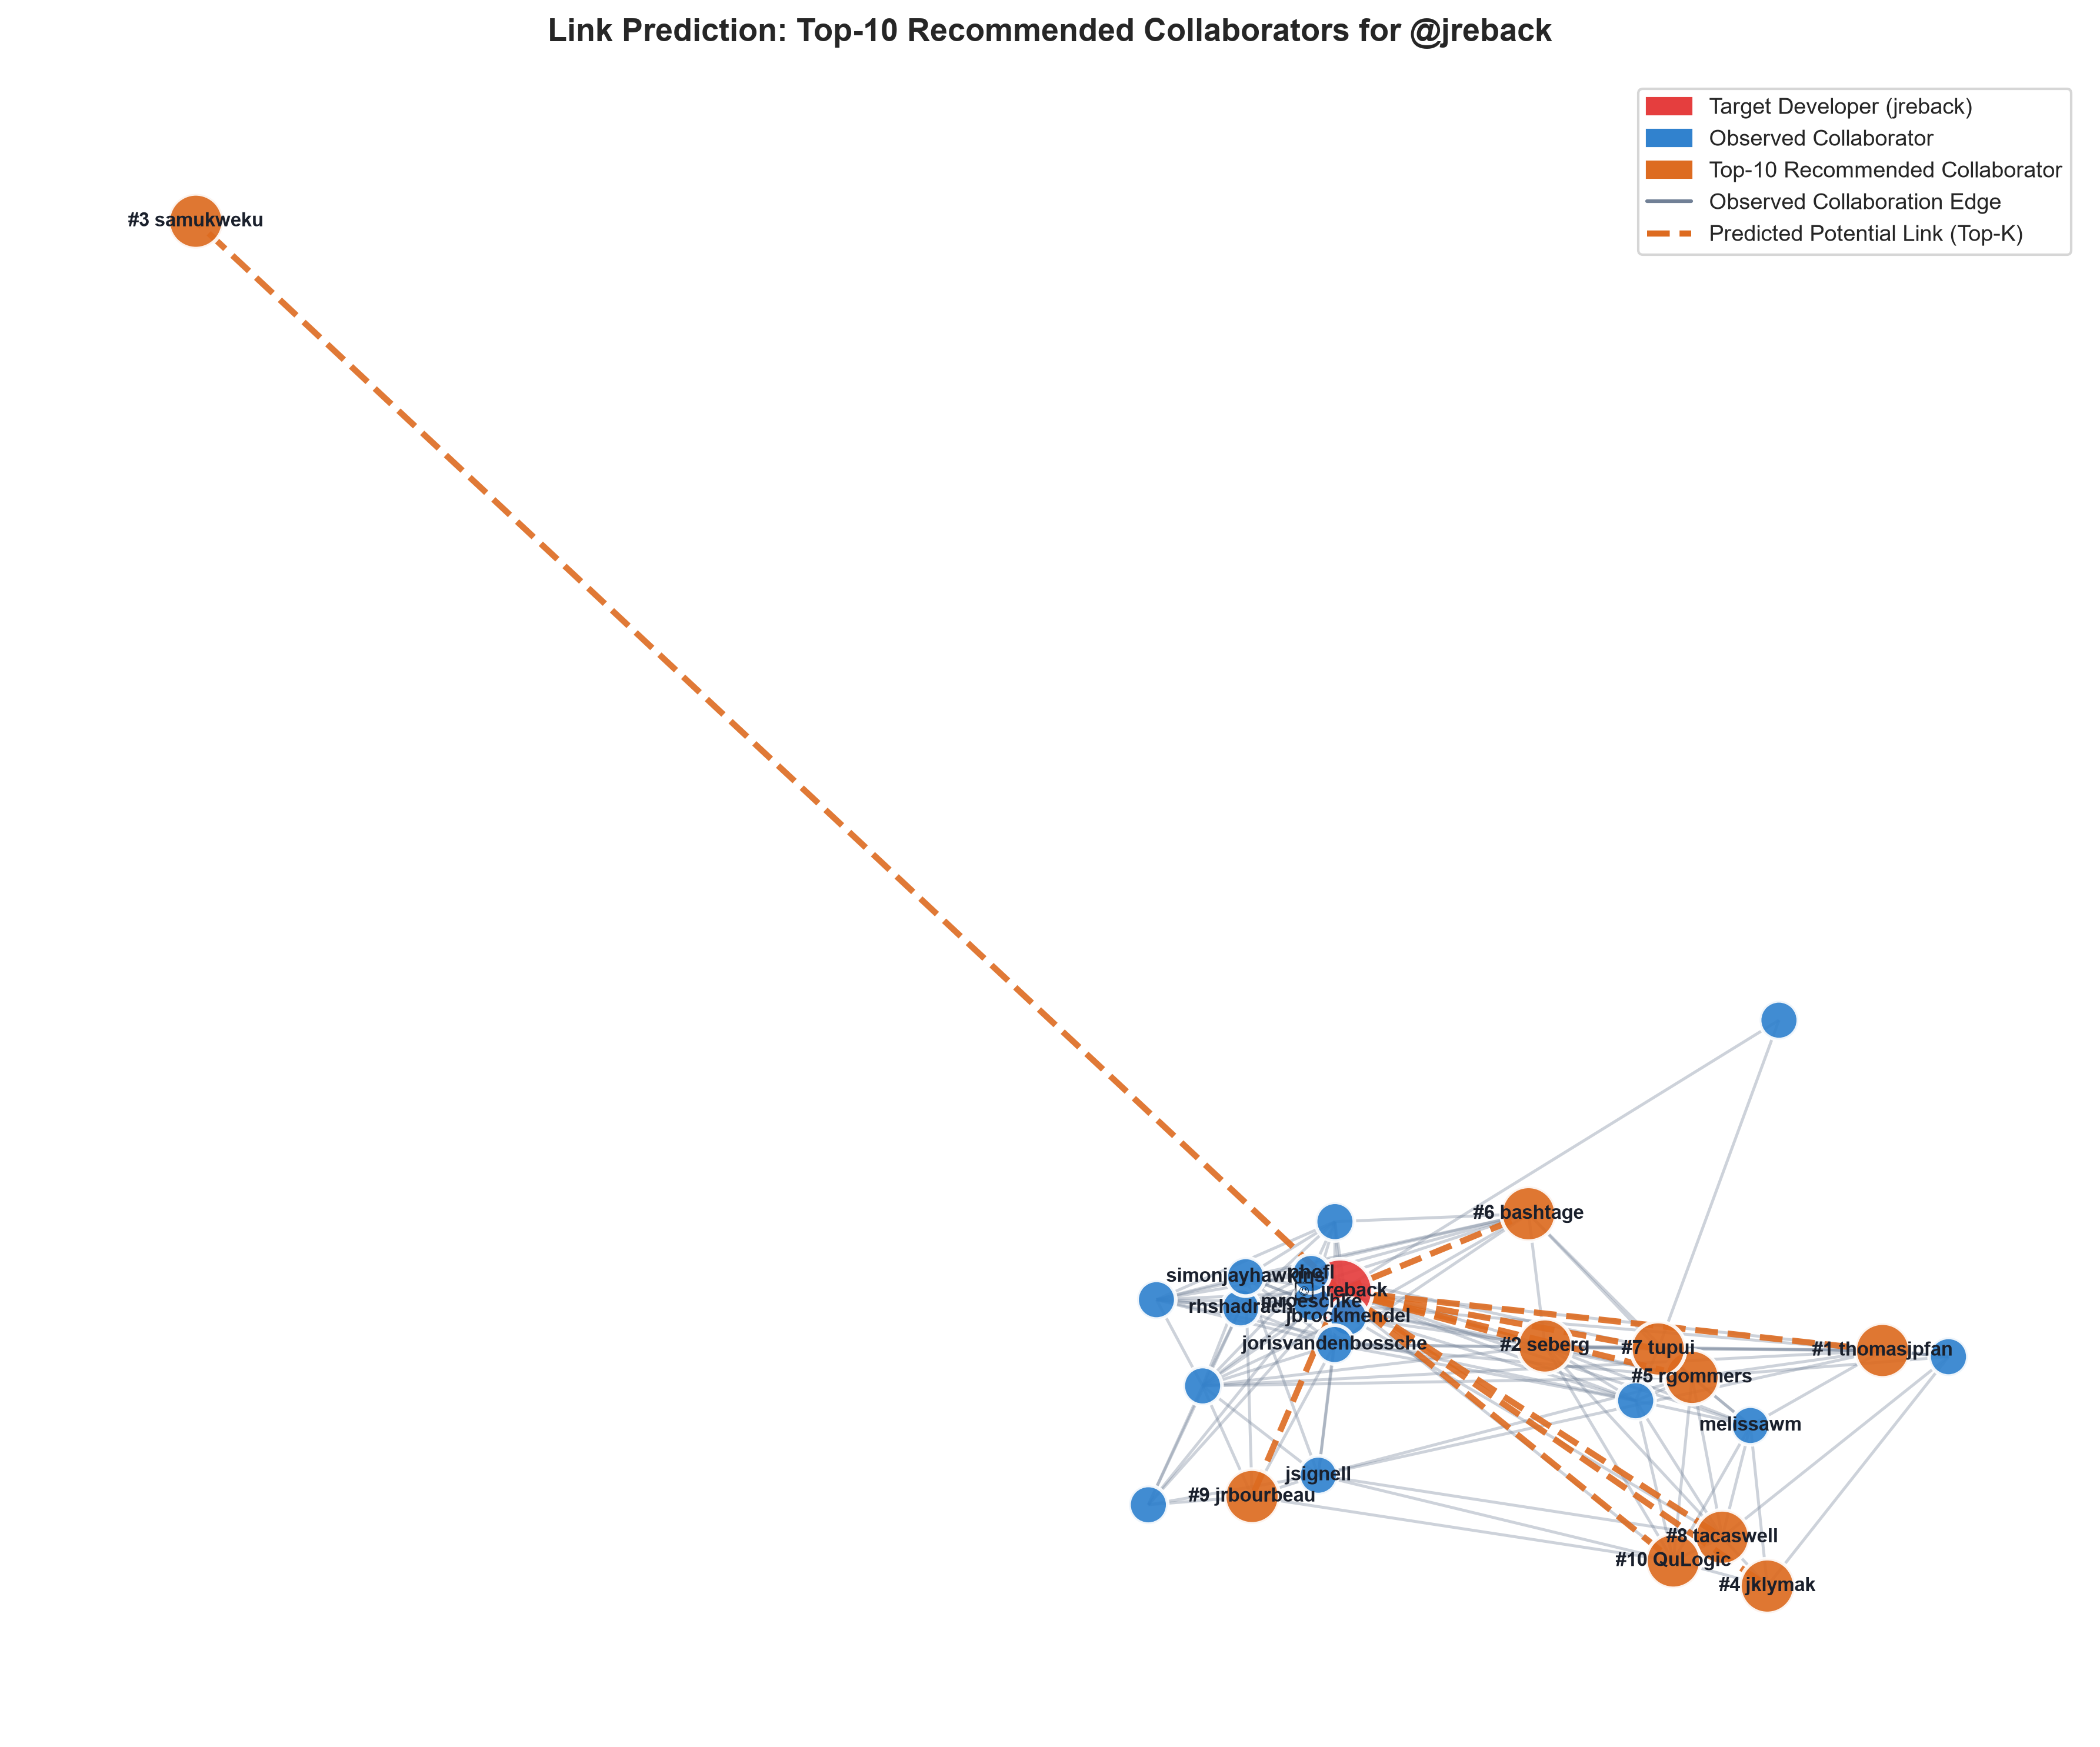

3. Comparative ROC Curves:


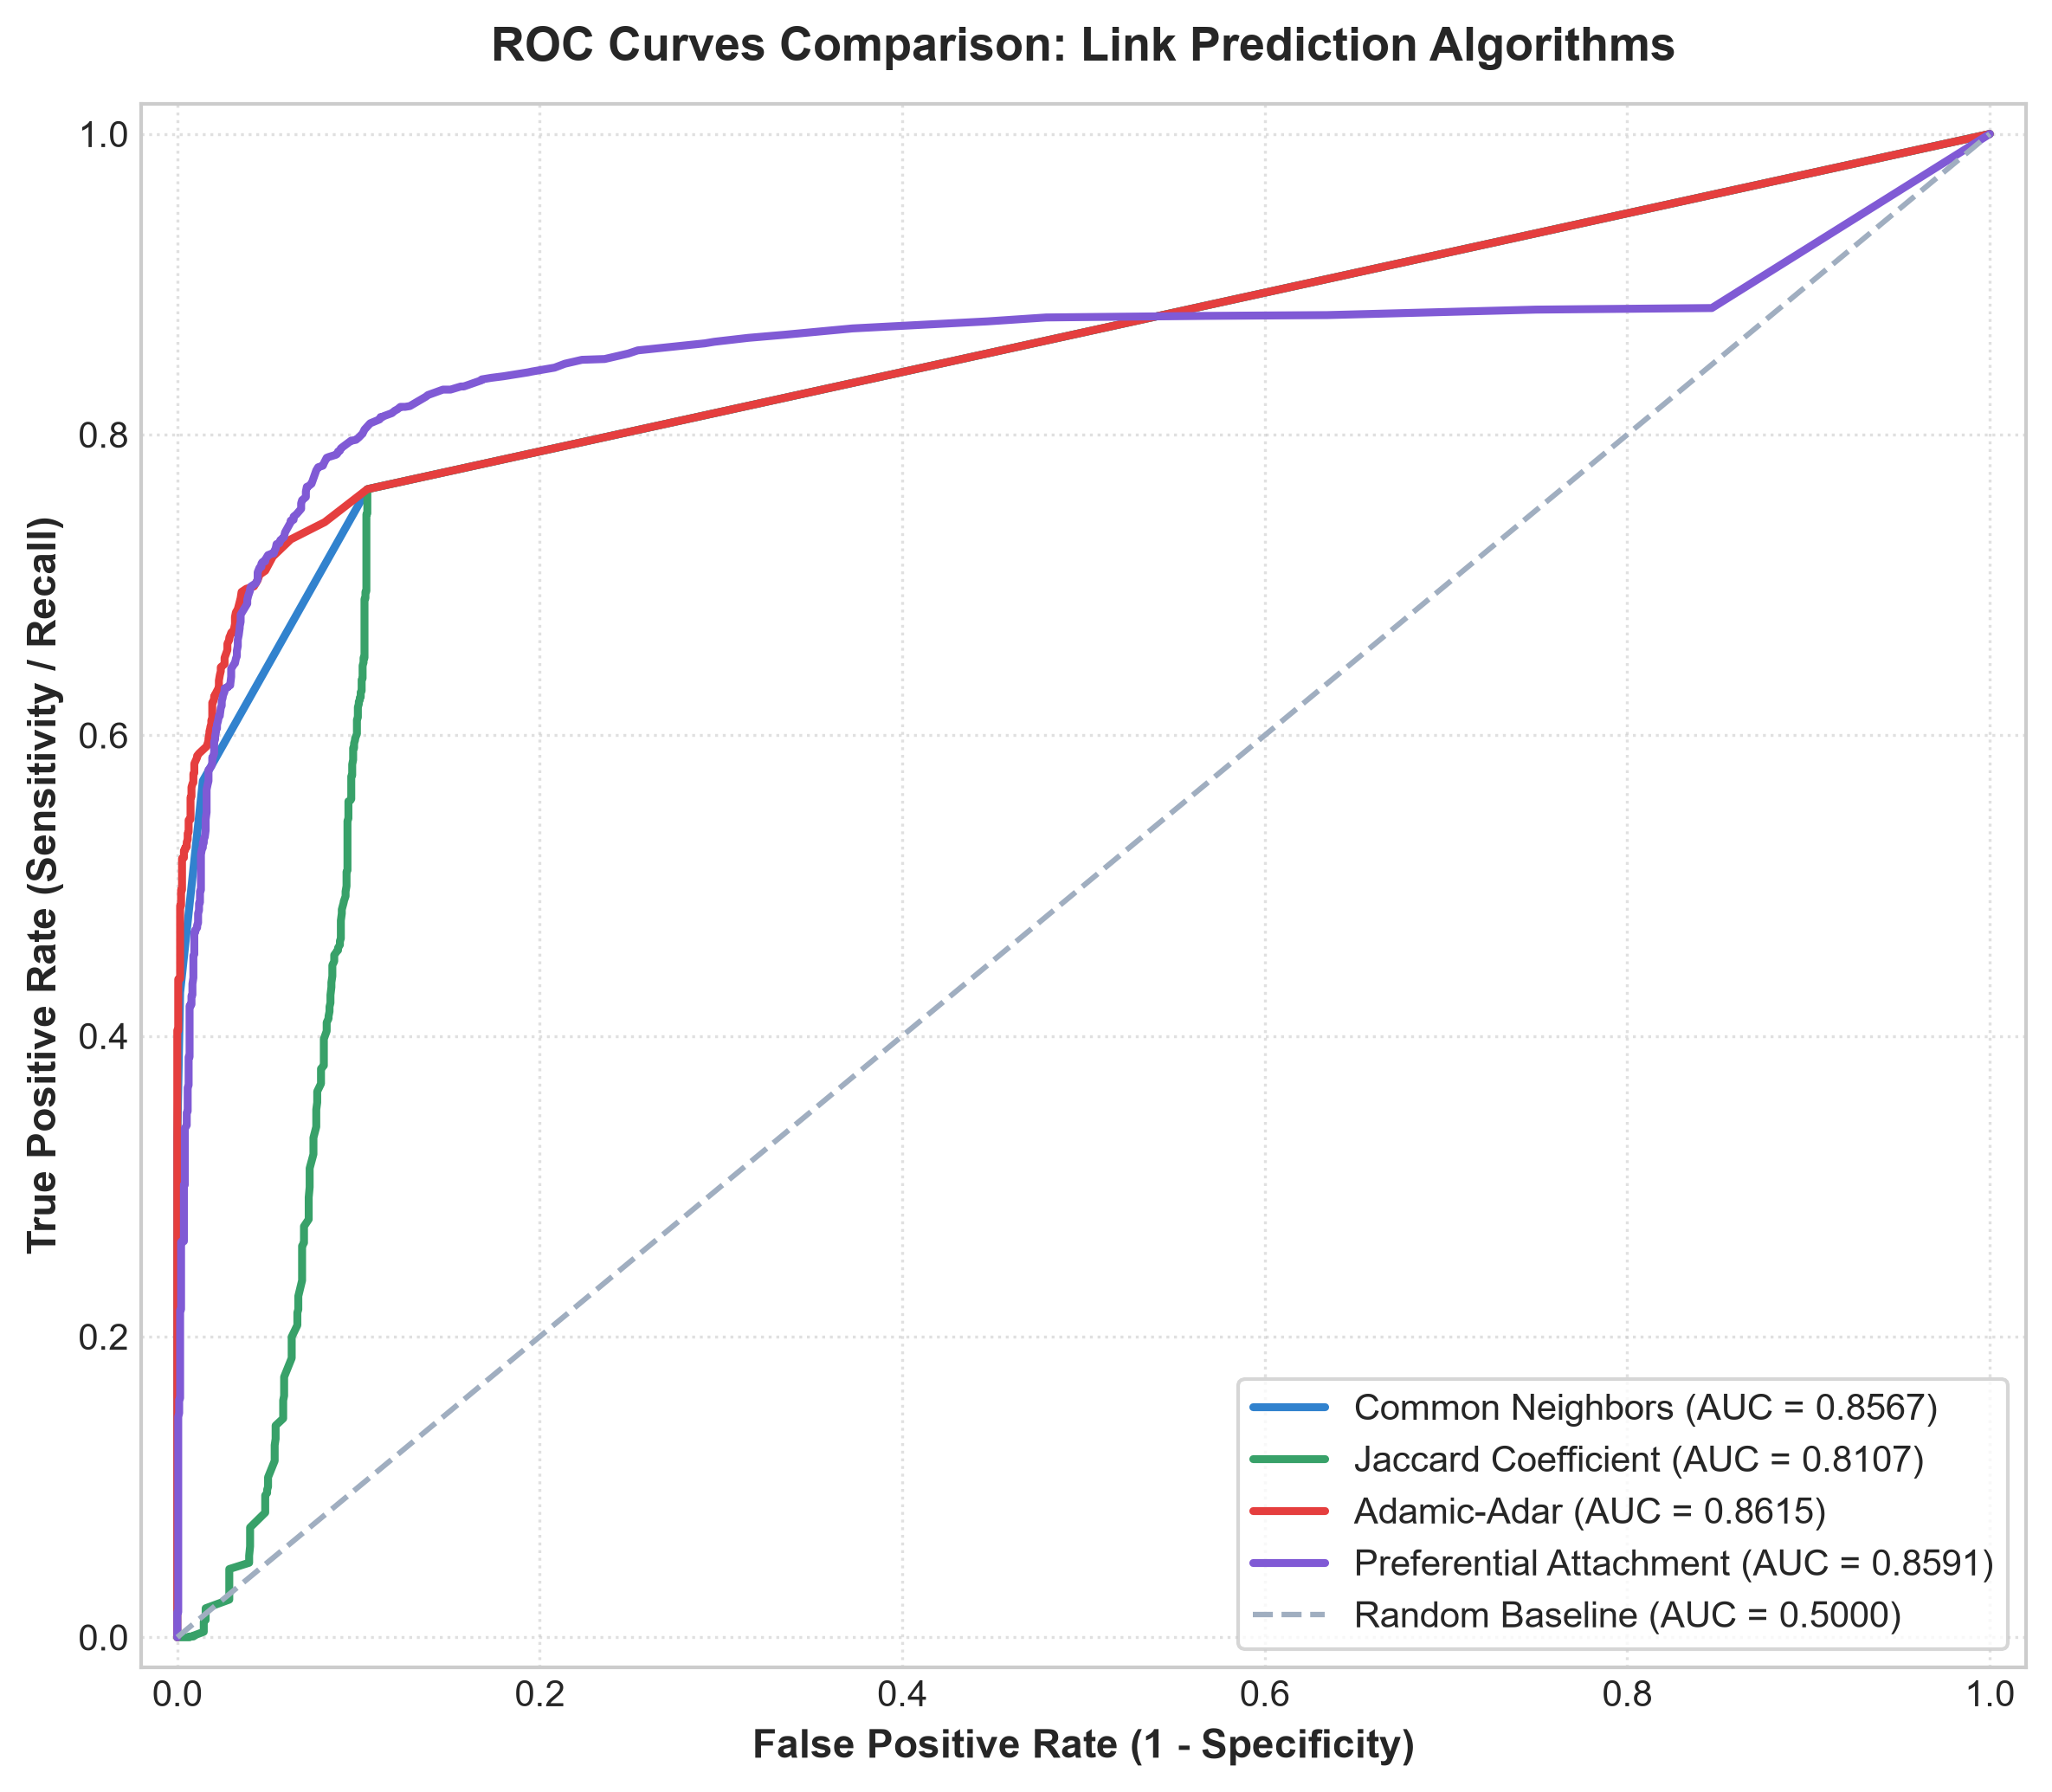

In [8]:
from IPython.display import Image, display

# Display generated high-resolution visualizations
print("1. Ego Network:")
display(Image(filename=str(DELIVERABLES_DIR / "network_ego.png"), width=650))

print("2. Link Prediction Overlay (Predicted edges in dashed orange):")
display(Image(filename=str(DELIVERABLES_DIR / "network_predictions.png"), width=650))

print("3. Comparative ROC Curves:")
display(Image(filename=str(DELIVERABLES_DIR / "roc_curves.png"), width=550))


## Step 7: Academic Deliverables Summary
All deliverables have been compiled and exported to the `deliverables/` directory:
- **Cytoscape GraphML:** `deliverables/developer_network.graphml`
- **Interactive Network Visualization:** `deliverables/interactive_network.html`
- **Academic PDF Report:** `deliverables/NumFOCUS_Collaboration_Report.pdf`
- **Presentation Deck:** `deliverables/NumFOCUS_Collaboration_Presentation.pptx`
- **Presentation PDF:** `deliverables/NumFOCUS_Collaboration_Presentation.pdf`
- **Viva Questions & Answers:** `deliverables/viva_questions_and_answers.md`
